# Домашнее задание 8 (10 pts)

Сопряжённые градиенты, тяжёлый шарик и метод Нестерова. Схемы итераций — на слайдах лекции, в задании они не повторяются.

На неделе 7 градиентный спуск с шагом $1/L$ на $\mu$-сильно выпуклой задаче тратит порядка $\kappa=L/\mu$ итераций. У методов этой недели в оценке стоит $\sqrt{\kappa}$.

База сравнения всюду одна — градиентный спуск с шагом $1/L$. По горизонтали откладывайте число умножений на матрицу или число вызовов градиента: у этих методов его один на итерацию.

Графики и письменный вывод обязательны в каждом пункте. Без комментария баллы за пункт не ставятся.


In [2]:
import numpy as np
import matplotlib.pyplot as plt


## Задача 1 (4 pts). Стационарная температура пластины

Квадратная пластина $(0,1)^2$, на границе температура нулевая, внутри два нагревателя. В стационаре

$$
-\Delta u = f.
$$

На сетке $n\times n$ внутренних узлов с шагом $h=1/(n+1)$ пятиточечный шаблон даёт систему $\mathbf{A}\mathbf{u}=\mathbf{b}$ с $\mathbf{A}=\mathbf{A}^\top\succ 0$. Саму матрицу не хранят: `apply_A` по вектору длины $n^2$ возвращает $\mathbf{A}\mathbf{u}$. Одно такое умножение — одна итерация каждого метода ниже.

Собственные значения шаблона

$$
\lambda_{p,q}
=
4\sin^2\frac{p\pi}{2(n+1)}
+
4\sin^2\frac{q\pi}{2(n+1)},
\qquad p,q=1,\ldots,n.
$$

Крайние из них, они же $\mu$ и $L$ квадратичной задачи,

$$
\mu=\lambda_{1,1}=8\sin^2\frac{\pi}{2(n+1)},
\qquad
L=\lambda_{n,n}=8\cos^2\frac{\pi}{2(n+1)},
\qquad
\kappa=\frac{L}{\mu}.
$$

Минимизируется энергия

$$
f(\mathbf{u})=\tfrac12\mathbf{u}^\top\mathbf{A}\mathbf{u}-\mathbf{b}^\top\mathbf{u}.
$$

Её градиент $\mathbf{g}(\mathbf{u})=\mathbf{A}\mathbf{u}-\mathbf{b}$ — невязка системы, минимум совпадает с решением. За $f^\star$ возьмите значение в точке, куда сопряжённые градиенты приходят с относительной невязкой $10^{-12}$.

Рассмотрим методы с лекции: градиентный спуск идёт с шагом $1/L$, тяжёлый шарик с оптимальными параметрами и линейный метод сопряжённых градиентов.


1. **(1.5 pts)** Возьмите $n=32$ и старт в нуле. Доведите относительную невязку $\|\mathbf{g}_k\|/\|\mathbf{g}_0\|$ до $10^{-6}$, бюджет — 8000 итераций.

   На одном графике с логарифмической осью $y$ покажите невязку трёх методов. В таблице приведите число итераций, $\kappa$ и $\sqrt{\kappa}$.

   Отдельно постройте $f(\mathbf{u}_k)-f^\star$ для сопряжённых градиентов и для тяжёлого шарика. Для каждого метода ответьте: убывает ли значение на каждом шаге и убывает ли невязка. Это разные свойства.

2. **(1.5 pts)** Для $n\in\{16,32,48,64\}$ доведите ту же невязку до $10^{-4}$. Бюджет градиентного спуска — 20000 итераций; если бюджета не хватило для сходимости, отметьте это.

   Постройте число итераций против $\kappa$ и против $\sqrt{\kappa}$. К какой из двух зависимостей ложится градиентный спуск и к какой — тяжёлый шарик и сопряжённые градиенты?

   Для $n=64$ нарисуйте две карты температуры в одной цветовой шкале: решение сопряжённых градиентов и точку градиентного спуска после стольких же итераций. По карте должно быть видно, успел ли градиентный спуск прогреть пластину за бюджет, которого хватило сопряжённым градиентам.

3. **(1 pt)** На $n=32$ запустите тяжёлый шарик на 200 итераций трижды: с верным $\mu$, с $\mu/10$ и с $\mu/100$. Величину $L$ не меняйте. На одном графике — относительная невязка, рядом — три получившихся $\beta$.

Объясните, почему заниженное $\mu$ увеличивает инерцию и за те же 200 шагов оставляет большую невязку.


In [3]:
def apply_A(u, n):
    """Пятиточечный лапласиан, снаружи сетки значение 0. Один вызов — одно умножение на A."""
    U = np.asarray(u, dtype=float).reshape(n, n)
    AU = 4.0 * U
    AU[:, 1:] -= U[:, :-1]
    AU[:, :-1] -= U[:, 1:]
    AU[1:, :] -= U[:-1, :]
    AU[:-1, :] -= U[1:, :]
    return AU.ravel()


def grid_rhs(n):
    """Правая часть: два нагревателя. Множитель h^2 переводит шаблон в аппроксимацию -Δu = f."""
    h = 1.0 / (n + 1)
    t = np.arange(1, n + 1) * h
    x, y = np.meshgrid(t, t, indexing="ij")
    source = np.exp(-((x - 0.35) ** 2 + (y - 0.62) ** 2) / 0.015)
    source += 0.7 * np.exp(-((x - 0.72) ** 2 + (y - 0.30) ** 2) / 0.008)
    return (h ** 2) * source.ravel()


def laplacian_bounds(n):
    """Точные μ и L пятиточечного шаблона."""
    s = np.sin(np.pi / (2 * (n + 1)))
    c = np.cos(np.pi / (2 * (n + 1)))
    return 8.0 * s ** 2, 8.0 * c ** 2


# Место для вашего решения


## Задача 2 (3 pts). Смазанный снимок

Камера сдвинулась за время выдержки и снимок смазался. Смазывание моделируется через свёртку резкого кадра с гауссовым ядром и шум:

$$
\mathbf{b}=\mathbf{K}\mathbf{u}_{\mathrm{sharp}}+\boldsymbol{\varepsilon}.
$$

Ядро на сетке $n\times n$ — гауссиан ширины $\sigma$ в пикселях. По периодической границе расстояние от узла до начала счёта $d(i)=\min(i,n-i)$,

$$
k_{ij}
=
C\exp\Bigl(-\frac{d(i)^2+d(j)^2}{2\sigma^2}\Bigr),
\qquad
\sum_{i,j}k_{ij}=1.
$$

Константа $C$ нормирует ядро на единицу. В коде $\sigma$ — это `sigma_blur`.

Свёртка $(\mathbf{K}\mathbf{u})$ с тем же периодом:

$$
(\mathbf{K}\mathbf{u})_{pq}
=
\sum_{a=0}^{n-1}\sum_{b=0}^{n-1}
k_{ab}\,u_{p-a,\,q-b},
$$

индексы $p-a$ и $q-b$ берутся по модулю $n$. Преобразование Фурье заменяет эту сумму произведением: собственные значения $\mathbf{K}$ — фурье-образ ядра, их возвращает `blur_eigs`.

Восстанавливается кадр $\mathbf{u}$. Штраф $\mu$ удерживает частоты, которые размытие почти занулило: без него шум на этих частотах раздувается в ложный рисунок.

$$
f(\mathbf{u})
=
\frac12\|\mathbf{K}\mathbf{u}-\mathbf{b}\|^2
+
\frac{\mu}{2}\|\mathbf{u}\|^2.
$$

Резкий кадр — файл `campus.jpg`. В $f$ этот кадр не входит: он нужен для оценки ошибки восстановления и для визуализации.
Ядро чётное, поэтому $\mathbf{K}=\mathbf{K}^\top$. Гессиан

$$
\mathbf{H}=\mathbf{K}^\top\mathbf{K}+\mu\mathbf{I}
$$

на вектор действует двумя свёртками, $\mathbf{H}\mathbf{v}=\mathbf{K}(\mathbf{K}\mathbf{v})+\mu\mathbf{v}$. Один вызов `apply_H` — одна итерация. Матрицу $n^2\times n^2$ не собирают. Спектр $\mathbf{H}$ лежит в $[\mu_H, L]$,

$$
\mu_H=\min_i\lambda_i(\mathbf{K})^2+\mu,
\qquad
L=\max_i\lambda_i(\mathbf{K})^2+\mu,
\qquad
\kappa=\frac{L}{\mu_H}.
$$

Градиент $\mathbf{g}(\mathbf{u})=\mathbf{H}\mathbf{u}-\mathbf{K}\mathbf{b}$. Вектор $\mathbf{K}\mathbf{b}$ посчитайте один раз.

Методы задачи 1 переносятся сюда: градиентный спуск с шагом $1/L$, тяжёлый шарик, сопряжённые градиенты. В формуле Поляка стоит $\mu_H$, а не штраф $\mu$. К ним добавляется метод Нестерова (определите подходящую версию метода) с шагом $1/L$. Старт в нуле. За $f^\star$ возьмите значение после сопряжённых градиентов с относительной невязкой $10^{-12}$. При другом $\mu$ заново посчитайте $\mu_H$, $L$, $\kappa$ и $f^\star$.


1. **(1.5 pts)** Возьмите штраф $\mu=10^{-4}$ из кода. Посчитайте $\kappa$. Запустите четыре метода, бюджет — 30000 итераций.

   На одном графике с логарифмической осью $y$ покажите $f(\mathbf{u}_k)-f^\star$. В таблице — $\kappa$, $\sqrt{\kappa}$ и итерация, на которой зазор впервые меньше $10^{-4}$. Если бюджет кончился раньше, так и запишите.

   На втором графике — средняя ошибка относительно резкого кадра,

$$
\mathrm{MSE}
=
\frac{1}{n^2}\|\mathbf{u}_k-\mathbf{u}_{\mathrm{sharp}}\|^2.
$$

   В итерации, где сопряжённые градиенты впервые берут допуск по зазору, нарисуйте четыре кадра: резкий кадр, наблюдение $\mathbf{b}$, восстановление сопряжённых градиентов и восстановление с помощью градиентного спуска. Ответьте, у какого метода в этот момент меньше зазор $f-f^\star$ и у какого меньше MSE. Зазор сравнивает кадр с наблюдением $\mathbf{b}$ и со штрафом, MSE сравнивает его с резким снимком.

2. **(1.5 pts)** Повторите эксперименты с четырьмя методами для $\mu\in\{10^{-2},\,10^{-3},\,10^{-4}\}$. Допуск по зазору $10^{-4}$, бюджет 30000. Для каждого $\mu$ заново посчитайте $\mu_H$, $L$, $\kappa$ и $f^\star$.

   Постройте число итераций против $\kappa$ и против $\sqrt{\kappa}$. К какой зависимости ложится градиентный спуск и к какой — тяжёлый шарик, метод Нестерова и сопряжённые градиенты?

   Для $\mu=10^{-4}$ постройте собственные значения $\mathbf{H}$ по возрастанию, ось $y$ логарифмическая. Спектр гауссова размытия спадает гладко, отдельных куч в нём нет. Поэтому число итераций сопряжённых градиентов остаётся порядка $\sqrt{\kappa}$: конечная остановка в размерности $n^2=262144$ лежит далеко за этим пределом.


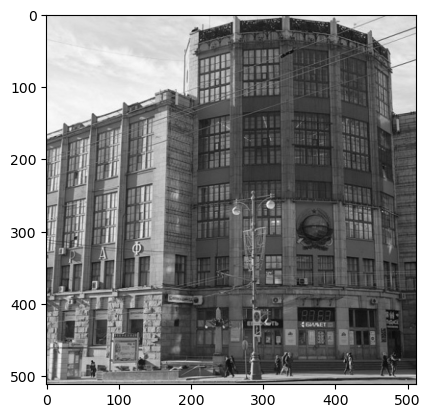

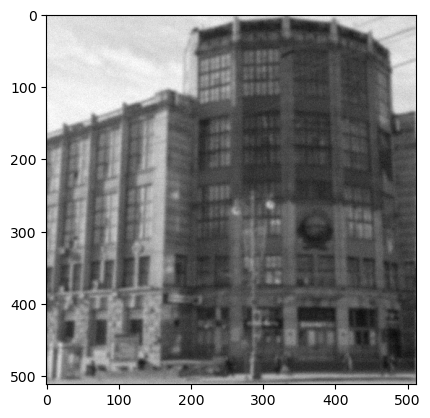

In [19]:
def blur_eigs(n, sigma):
    """Собственные значения гауссовой свёртки с периодической границей."""
    ax = np.arange(n)
    dist = np.minimum(ax, n - ax).astype(float)
    xx, yy = np.meshgrid(dist, dist, indexing="ij")
    ker = np.exp(-(xx ** 2 + yy ** 2) / (2.0 * sigma ** 2))
    ker /= ker.sum()
    return np.fft.fft2(ker).real


def apply_K(u, eigvals):
    """Одна свёртка. eigvals — то, что вернул blur_eigs."""
    U = np.asarray(u, dtype=float).reshape(eigvals.shape)
    return np.fft.ifft2(eigvals * np.fft.fft2(U)).real.ravel()


def apply_H(u, eigvals, mu):
    """H v = K(Kv) + μ v. Один вызов — одна итерация."""
    v = np.asarray(u, dtype=float).ravel()
    return apply_K(apply_K(v, eigvals), eigvals) + mu * v


def load_sharp(path, n):
    """Яркость campus.jpg: центральный квадрат n×n исходных пикселей.
    В целевую функцию не входит.
    """
    rgb = np.asarray(plt.imread(path), dtype=float)
    if rgb.max() > 1.5:
        rgb = rgb / 255.0
    gray = rgb[..., :3] @ np.array([0.2989, 0.5870, 0.1140])
    height, width = gray.shape
    top = (height - n) // 2
    left = (width - n) // 2
    return gray[top:top + n, left:left + n]


n = 512
sigma_blur = 2.0
mu_penalty = 1e-4
eigvals = blur_eigs(n, sigma_blur)
sharp = load_sharp("campus.jpg", n).ravel()
rng = np.random.default_rng(8)
blurred = apply_K(sharp, eigvals)
b = blurred + 0.1 * np.std(blurred) * rng.normal(size=blurred.shape)
plt.imshow(sharp.reshape(n, n), cmap="gray", vmin=0, vmax=1)
plt.show()
plt.imshow(b.reshape(n, n), cmap="gray", vmin=0, vmax=1)
# Место для вашего решения


## Задача 3 (3 pts). Две спектральные линии

Спектрометр записал сумму двух линий $\mathbf{y}$. Ширина $\sigma$ и интенсивности $a_1$, $a_2$ известны по калибровке прибора, положения $m_1$ и $m_2$ — нет. На сетке $x_i$

$$
\varphi_\sigma(t)=\exp\!\left(-\frac{t^2}{2\sigma^2}\right),
\qquad
\mathbf{s}_i(\mathbf{m})
=
\,a_1\,\varphi_\sigma(x_i-m_1)
+
\,a_2\,\varphi_\sigma(x_i-m_2).
$$

Подгоняется средний квадрат невязки

$$
\,f(\mathbf{m})
=
\frac1{2N}\|\mathbf{s}(\mathbf{m})-\mathbf{y}\|^2.
$$

Первая компонента несёт амплитуду $a_1=1$, вторая — $a_2=0{,}55$. Переставить положения значит повесить большую амплитуду на слабую линию: это другой вектор и другое значение $f$. Истинные положения в $f$ не входят.

Градиент $f$ по положениям нужно вывести и реализовать в пункте 1. Постоянной матрицы $\mathbf{A}$ нет, поэтому схема сопряжённых градиентов из задачи 1 к этой $f$ не переносится. Но переносится обобщение на неквадратичную задачу (метод Полака-Рибьера).

Целевая функция $f$ гладкая и невыпуклая. В начале координат оба собственных значения гессиана отрицательны, так что константы сильной выпуклости на всём пространстве нет. Локальных минимумов несколько. В каждом градиент обращается в нуль, а значения $f$ различаются на порядки.

Итерации тяжёлого шарика, метода Нестерова с и без рестартов а также метд Полака-Рибьера были приведены на слайдах.


1. **(1 pt)** Выведите $\partial f/\partial m_j$ и реализуйте `loss_and_grad(means)`. Функция возвращает значение $f$ и градиент длины 2. Модель $\mathbf{s}(\mathbf{m})$ уже есть в `spectrum`.

   Проверка — в точке $(-1{,}2,\, 0{,}8)$ сравните с результатом автоматического дифференцирования.

2. **(1 pt)** Запустите градиентный спуск с шагом $1/L$ из трёх стартов, которые лежат в коде. Бюджет — 500 вызовов градиента. Оцените $L$, чтобы наблюдалась наилучшая сходимость. 

   На квадрате $[-5,5]^2$ нарисуйте линии уровня $f$ и три траектории. В таблице — финальные $(m_1,m_2)$, значение $f$ и $\|f'\|$. Для каждого старта нарисуйте запись $\mathbf{y}$ и спектр $\mathbf{s}(\mathbf{m})$, который даёт `spectrum`.

   В комментарии:

   - убывает ли $f$ на каждом шаге;
   - в каких финальных точках градиент уже мал, а $f$ далеко от наименьшего из трёх значений;
   - почему проверка $\|f'\|<\varepsilon$ не отличает глобальный минимум, когда выпуклости нет;
   - что именно сломалось в двух худших подгонках: амплитуды сели на чужие линии или обе компоненты съехались на одном пике.

3. **(1 pt)** Возьмите старт $(-1{,}2,\, 0{,}8)$. Запустите из этой же точки метод тяжёлого шарика, метод Нестерова с рестартом и без и нелинейный метод сопряжённых градиентов.
Бюджет — 2000 вызовов градиента. Сравните сходимость методов и проанализируйте траектории.
   В комментарии:
   - убывает ли $f$ на каждом шаге;
   - сколько раз сработал рестарт и что на этой $f$ видно у схемы с $t_k$ без рестарта.


In [17]:
def spectrum(means):
    """Модель s(m) на сетке x."""
    means = np.asarray(means, dtype=float)
    s = np.zeros_like(x)
    for amp, center in zip((a1, a2), means):
        s += amp * np.exp(-0.5 * ((x - center) / sigma) ** 2)
    return s


def loss_and_grad(means):
    """Пункт 1. Верните f(m) и градиент по двум положениям.
    Один вызов — одна итерация.
    """
    raise NotImplementedError


N = 120
x = np.linspace(-7.0, 7.0, N)
sigma = 0.6
a1, a2 = 1.0, 0.55
L = 0.15
rng = np.random.default_rng(3)
m_true = np.array([-2.4, 2.0])
y = spectrum(m_true) + 0.015 * rng.normal(size=N)

starts = (
    np.array([-1.2, 0.8]),
    np.array([1.2, -1.0]),
    np.array([-3.2, -1.2]),
)

# Место для вашего решения

